# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [3]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.1.3
Pandas version: 2.2.3


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [5]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = (0.3, 0.7)
bias = 0.5

# 1. Compute linear combination z
z =  S @ np.array([0.3, 0.7]) + 0.5

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5) 
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails 
predicted_spam = probabilities >= 0.5

In [6]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities) 
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [9]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})


In [ ]:
# Auto graded cell (log)
# skip it

In [10]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

log.loc[rng.choice(n, 12, replace=False), "failed_attempts"] = rng.integers(5, 11, 12)

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [13]:
# Insert 10 missing values randomly
for i in range(10):
    row = rng.integers(0, n)
    col = rng.choice(log.columns)
    log.loc[row, col] = np.nan


In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [12]:
# Write your code here
df = log.copy()
ru_log_at_least_five_attempts = df[(df["failed_attempts"] >= 5) & (df["country"] != "RU")]

In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [19]:
# Write your code here
user_max_failed_attempts = (df.groupby("user")["failed_attempts"].sum().sort_values(ascending=False))

In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [21]:
# Write your code here
df['long_session'] = (df["duration_min"] > 30).astype(int)
log["long_session"] = df["long_session"]

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

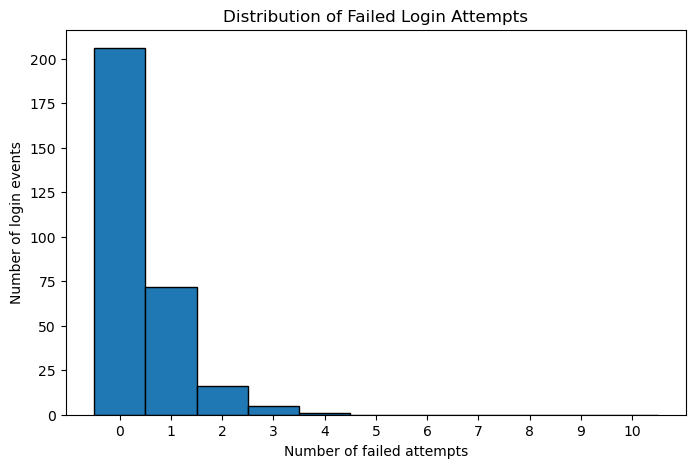

In [18]:
# Draw the histogram of failed_attempts.
values = df["failed_attempts"].dropna()
plt.figure(figsize=(8, 5))
plt.hist(values, bins=np.arange(-0.5, 11.5, 1), edgecolor="black")
plt.title("Distribution of Failed Login Attempts")
plt.xlabel("Number of failed attempts")
plt.ylabel("Number of login events")
plt.xticks(range(0, 11))
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
answer = "B"

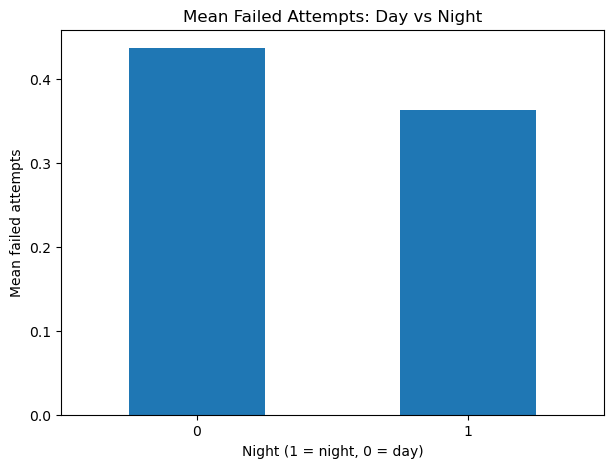

In [19]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
df["night"] = ((df["hour"] >= 22) | (df["hour"] < 6)).astype(int)
mean_failed_by_night = df.groupby("night")["failed_attempts"].mean()

plt.figure(figsize=(7, 5))
mean_failed_by_night.plot(kind="bar")
plt.title("Mean Failed Attempts: Day vs Night")
plt.xlabel("Night (1 = night, 0 = day)")
plt.ylabel("Mean failed attempts")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
q1 = "X[:, 2] returns all rows from the third column."

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [23]:
# Write your code here
df.isna().sum()


user               0
hour               0
failed_attempts    0
country            0
duration_min       0
long_session       0
dtype: int64

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
q3 = "Box plot"

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
q4 = "We scale features before training a model to prevent variables with larger numerical ranges from dominating the learning process and to ensure faster, more stable convergence during optimization."

Commit the logins_clean.csv.(0.5 point)

In [2]:
# save the cleaned table in login_clean.csv
# Write your code here
df.to_csv("logins_clean.csv", index=False)

NameError: name 'df' is not defined

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [4]:
# Write your code here
from sklearn.preprocessing import StandardScaler
clean_df = pd.read_csv("logins_clean.csv")

clean_df["night"] = (
    (clean_df["hour"] >= 22) | (clean_df["hour"] < 6)
).astype(int)

cols = ["hour", "failed_attempts", "duration_min", "night"]

X = clean_df[cols].to_numpy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X shape:", X.shape)
print("Scaled X shape:", X_scaled.shape)

NameError: name 'pd' is not defined

In [ ]:
import numpy as np
import pandas as pd
